# 04 · Obesidad: modelado

Proyecto del curso Machine Learning (650064), Universidad de Lima, ciclo 2026-2.  
**Objetivo del notebook:** entrenar y comparar los modelos de referencia y los métodos nuevos (KNN y MLP) en los dos escenarios; el escenario principal es E2 (sin estatura ni peso).  
**Decisiones:** `documentacion/diseno_experimental.md` (las secciones del diseño se citan como §).

## Autores por sección

| Sección | Autor |
|---|---|
| Todas las secciones de este notebook | Marcelo Cueto |
| Funciones de `utilidades.py` | Marcelo Cueto |

## 0. Configuración

**Qué hacemos:** preparamos el entorno y cargamos las librerías.

**Por qué:** la celda 0 hace que el mismo notebook funcione en VS Code y en Colab, con las versiones fijadas en `requirements.txt`.

In [1]:
# Celda 0. Configuración del entorno: funciona igual en VS Code y en Colab.
import os
import sys

EN_COLAB = "google.colab" in sys.modules
USUARIO_GITHUB = "MCuetoV"
REPOSITORIO = "proyecto-ml-2026-2"

if EN_COLAB:
    # En Colab: clonar el repositorio (o actualizarlo) con el token guardado en Secrets
    from google.colab import userdata
    token = userdata.get("GITHUB_TOKEN")
    if not os.path.exists(f"/content/{REPOSITORIO}"):
        !git clone -q https://{token}@github.com/{USUARIO_GITHUB}/{REPOSITORIO}.git /content/{REPOSITORIO}
    os.chdir(f"/content/{REPOSITORIO}")
    !git pull -q
    !pip install -q -r requirements.txt
else:
    # En VS Code: si el notebook se abrió desde notebooks/, subir a la raíz del repositorio
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")

print("Carpeta de trabajo:", os.getcwd())

Carpeta de trabajo: /Users/marce/Documents/CURSOS_UNIVERSIDAD/MachineLearning/proyecto-ml-2026-2


In [2]:
# Librerías y funciones comunes del proyecto
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import utilidades

pd.set_option("display.max_columns", 50)
print("Semilla del proyecto:", utilidades.SEMILLA)

Semilla del proyecto: 42


In [3]:
# Librerías del modelado
import time
import warnings
import numpy as np
import optuna
from optuna.samplers import TPESampler
from scipy.stats import wilcoxon
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from imblearn.pipeline import Pipeline   # admite pasos de remuestreo dentro del Pipeline

optuna.logging.set_verbosity(optuna.logging.WARNING)   # sin un mensaje por cada trial

/Users/marce/Documents/CURSOS_UNIVERSIDAD/MachineLearning/proyecto-ml-2026-2/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Carga, escenarios y partición

**Qué hacemos:** cargamos los datos, recuperamos la partición del notebook de exploración y definimos las variables de cada escenario y las particiones de la validación cruzada.

**Por qué:** todos los modelos se comparan con las mismas filas, las mismas variables y los mismos *folds* (diseño, §7). El target se codifica como enteros porque `MLPClassifier` de scikit-learn 1.6.1 falla con *early stopping* y clases de texto; en obesidad los enteros siguen el orden de severidad, que usa el kappa ponderado.

In [4]:
# Datos, partición única (§7), escenarios (§1) y validación cruzada agrupada de 5 folds
SEMILLA = utilidades.SEMILLA
datos = utilidades.cargar_obesidad()
train, test = utilidades.dividir_train_test(datos, "obesidad")
y_train = utilidades.codificar_objetivo(train[utilidades.OBJETIVO_OBESIDAD], "obesidad")
y_test = utilidades.codificar_objetivo(test[utilidades.OBJETIVO_OBESIDAD], "obesidad")
CLASES = utilidades.ORDEN_OBESIDAD
ETIQUETAS = ["Peso insuficiente", "Normal", "Sobrepeso I", "Sobrepeso II", "Obesidad I", "Obesidad II", "Obesidad III"]
GRUPOS = train["grupo"]            # filas idénticas siempre en el mismo fold
CV = utilidades.particiones_agrupadas(y_train, GRUPOS, SEMILLA)       # mismos folds que evaluar_cv
ESCENARIOS = {esc: utilidades.columnas_por_escenario("obesidad", esc) for esc in ["E1", "E2"]}
PRINCIPAL = "E2"
print("Train:", len(train), "· Test:", len(test), "·", {e: len(v) for e, v in ESCENARIOS.items()})
filas_resultados = []   # registro de resultados de este notebook (§11.2)

Train: 1671 · Test: 416 · {'E1': 16, 'E2': 14}


## 2. Pipeline de preprocesamiento

**Qué hacemos:** definimos una función que arma el `Pipeline` de cada modelo y revisamos cuántas columnas produce la codificación.

**Por qué:** la codificación, el escalado y la selección van dentro del `Pipeline`, así que en la CV se aprenden en cada fold y nunca ven la validación ni el test (diseño, §4.2 y §6).

In [5]:
# Pipeline: codificación y escalado → [selector L1] → modelo (en obesidad no se remuestrea, §5)
def crear_pipeline(modelo, escenario, balanceo=False, seleccion=False):
    pasos = [("preprocesamiento", utilidades.crear_preprocesador("obesidad", escenario))]
    if seleccion:
        lasso = LogisticRegression(penalty="l1", solver="saga", C=1.0, max_iter=5000)
        pasos.append(("seleccion", SelectFromModel(lasso)))
    pasos.append(("modelo", modelo))
    return Pipeline(pasos)

In [6]:
# Columnas que produce la codificación en cada escenario (ajustada solo con el train)
for escenario, columnas in ESCENARIOS.items():
    matriz = utilidades.crear_preprocesador("obesidad", escenario).fit_transform(train[columnas])
    print(escenario, "→", len(columnas), "variables originales →", matriz.shape[1], "columnas")

E1 → 16 variables originales → 19 columnas
E2 → 14 variables originales → 17 columnas


**Qué observamos:** la codificación produce 19 columnas en E1 y 17 en E2. Son pocas porque MTRANS es la única nominal (Bike y Motorbike se agrupan como infrecuentes) y cada binaria ocupa una sola columna.

## 3. Modelos de referencia

**Qué hacemos:** entrenamos el piso trivial y el método de los autores en cada escenario.

**Por qué:** el Dummy es el piso: cualquier modelo útil debe superarlo. El árbol de decisión aproxima el J48 de De-La-Hoz-Correa et al. (2019); se usa `criterion="entropy"` porque C4.5 también se basa en la ganancia de información, pero CART no es C4.5 (cortes binarios y otra poda) y así se declara. Se ajusta con `GridSearchCV`, visto en clase (diseño, §2.2).

In [7]:
# Piso: el Dummy siempre predice la clase más frecuente del train
MODELOS_FINALES = {}   # (modelo, escenario) → Pipeline sin entrenar; se evalúan en §8 y §9
HIPERPARAMETROS = []   # filas de la tabla 2
for escenario in ESCENARIOS:
    MODELOS_FINALES[("Dummy", escenario)] = crear_pipeline(DummyClassifier(strategy="most_frequent"), escenario)

In [8]:
# Referencia de los autores: árbol de decisión (aproximación a J48), ajustado con GridSearchCV
MALLA_ARBOL = {"modelo__max_depth": [3, 5, 8, 12, None], "modelo__min_samples_leaf": [1, 5, 10]}
for escenario, columnas in ESCENARIOS.items():
    arbol = crear_pipeline(DecisionTreeClassifier(criterion="entropy", random_state=SEMILLA), escenario)
    busqueda = GridSearchCV(arbol, MALLA_ARBOL, cv=CV, scoring="f1_macro", n_jobs=-1).fit(train[columnas], y_train)
    parametros = {k.replace("modelo__", ""): v for k, v in busqueda.best_params_.items()}
    modelo = DecisionTreeClassifier(criterion="entropy", random_state=SEMILLA, **parametros)
    MODELOS_FINALES[("Árbol (autores)", escenario)] = crear_pipeline(modelo, escenario)
    HIPERPARAMETROS.append({"modelo": "Árbol (autores)", "escenario": escenario, "busqueda": "GridSearchCV",
                            "evaluaciones": len(busqueda.cv_results_["params"]),
                            "mejor_macro_f1_cv": busqueda.best_score_, "hiperparametros": parametros})
pd.DataFrame(HIPERPARAMETROS).round(3)

,modelo,escenario,busqueda,evaluaciones,mejor_macro_f1_cv,hiperparametros
0,Árbol (autores),E1,GridSearchCV,15,0.942,"{'max_depth': None, 'min_samples_leaf': 1}"
1,Árbol (autores),E2,GridSearchCV,15,0.665,"{'max_depth': 12, 'min_samples_leaf': 1}"


**Qué observamos:** el árbol de decisión alcanza un macro-F1 de 0.942 en E1, sin límite de profundidad, y 0.665 en E2, con profundidad 12. La caída de casi 0.28 al quitar estatura y peso confirma que la etiqueta depende sobre todo del IMC.

## 4. Ajuste con Optuna: KNN y MLP

**Qué hacemos:** buscamos los hiperparámetros de KNN (50 *trials*) y del MLP (100 *trials*) con el muestreador TPE de Optuna, en cada escenario.

**Por qué:** cumple las estrategias (a) y (b) de la consigna. TPE propone cada nueva configuración según los resultados de las anteriores, en vez de probar todas las combinaciones de una malla. El objetivo es el macro-F1 medio de una CV de 5 folds sobre el train (diseño, §8).

In [9]:
# Espacio de búsqueda de cada modelo (diseño, §8). trial.suggest_* elige un valor en cada intento.
def crear_knn(trial):
    return KNeighborsClassifier(n_neighbors=trial.suggest_int("n_neighbors", 1, 50),
                                weights=trial.suggest_categorical("weights", ["uniform", "distance"]),
                                p=trial.suggest_categorical("p", [1, 2]))   # 1 Manhattan, 2 euclídea

def crear_mlp(trial):
    capas = trial.suggest_int("capas", 1, 3)
    neuronas = tuple(trial.suggest_int(f"neuronas_{i + 1}", 16, 256, log=True) for i in range(capas))
    return MLPClassifier(hidden_layer_sizes=neuronas,
        activation=trial.suggest_categorical("activation", ["relu", "tanh"]),
        solver=trial.suggest_categorical("solver", ["adam", "sgd"]), momentum=0.9,
        alpha=trial.suggest_float("alpha", 1e-6, 1e-1, log=True),
        learning_rate_init=trial.suggest_float("learning_rate_init", 1e-4, 1e-1, log=True),
        batch_size=trial.suggest_categorical("batch_size", [32, 64, 128, 256]),
        early_stopping=True, validation_fraction=0.1, max_iter=500, random_state=SEMILLA)

In [10]:
# Pipeline completo a partir de un trial (o de los mejores parámetros, con FixedTrial)
def pipeline_desde_trial(trial, nombre, escenario, seleccion=False):
    modelo = crear_knn(trial) if nombre == "KNN" else crear_mlp(trial)
    return crear_pipeline(modelo, escenario, seleccion=seleccion)

def objetivo(trial, nombre, escenario):
    pipeline = pipeline_desde_trial(trial, nombre, escenario)
    columnas = ESCENARIOS[escenario]
    return utilidades.evaluar_cv(pipeline, train[columnas], y_train, grupos=GRUPOS).mean()

In [11]:
# Búsqueda con TPE. Los avisos de no convergencia de algunos trials se silencian aquí;
# la convergencia de las configuraciones finales se revisa en la sección 9.
ESTUDIOS = {}
for escenario in ESCENARIOS:
    for nombre, n_trials in [("KNN", 50), ("MLP", 100)]:
        estudio = optuna.create_study(direction="maximize", sampler=TPESampler(seed=SEMILLA))
        inicio = time.time()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            estudio.optimize(lambda trial: objetivo(trial, nombre, escenario), n_trials=n_trials)
        ESTUDIOS[(nombre, escenario)] = {"estudio": estudio, "segundos": time.time() - inicio}
        print(f"{nombre} {escenario}: mejor macro-F1 CV = {estudio.best_value:.3f} "
              f"({n_trials} trials, {time.time() - inicio:.0f} s)")

KNN E1: mejor macro-F1 CV = 0.821 (50 trials, 5 s)


MLP E1: mejor macro-F1 CV = 0.957 (100 trials, 31 s)


KNN E2: mejor macro-F1 CV = 0.670 (50 trials, 5 s)


MLP E2: mejor macro-F1 CV = 0.720 (100 trials, 29 s)


In [12]:
# Configuraciones finales de KNN y MLP: los mejores parámetros de cada estudio
for (nombre, escenario), resultado in ESTUDIOS.items():
    estudio = resultado["estudio"]
    MODELOS_FINALES[(nombre, escenario)] = pipeline_desde_trial(
        optuna.trial.FixedTrial(estudio.best_params), nombre, escenario)
    HIPERPARAMETROS.append({"modelo": nombre, "escenario": escenario, "busqueda": "Optuna (TPE)",
                            "evaluaciones": len(estudio.trials), "mejor_macro_f1_cv": estudio.best_value,
                            "hiperparametros": estudio.best_params})
tabla_hiperparametros = pd.DataFrame(HIPERPARAMETROS)
tabla_hiperparametros.round(3)

,modelo,escenario,busqueda,evaluaciones,mejor_macro_f1_cv,hiperparametros
0,Árbol (autores),E1,GridSearchCV,15,0.942,"{'max_depth': None, 'min_samples_leaf': 1}"
1,Árbol (autores),E2,GridSearchCV,15,0.665,"{'max_depth': 12, 'min_samples_leaf': 1}"
2,KNN,E1,Optuna (TPE),50,0.821,"{'n_neighbors': 3, 'weights': 'distance', 'p': 1}"
3,MLP,E1,Optuna (TPE),100,0.957,"{'capas': 3, 'neuronas_1': 195, 'neuronas_2': ..."
4,KNN,E2,Optuna (TPE),50,0.670,"{'n_neighbors': 5, 'weights': 'distance', 'p': 1}"
5,MLP,E2,Optuna (TPE),100,0.720,"{'capas': 2, 'neuronas_1': 166, 'neuronas_2': ..."


**Qué observamos:** en E1, KNN llega a 0.821 (3 vecinos, ponderados por distancia, distancia Manhattan) y el MLP a 0.957 (3 capas de 195, 56 y 72 neuronas, tanh y Adam). En E2, KNN llega a 0.670 (5 vecinos) y el MLP a 0.720 (2 capas de 166 y 158 neuronas, ReLU, Adam y regularización L2 con alpha = 0.010). KNN prefiere pocos vecinos en ambos escenarios: decide por la vecindad más cercana.

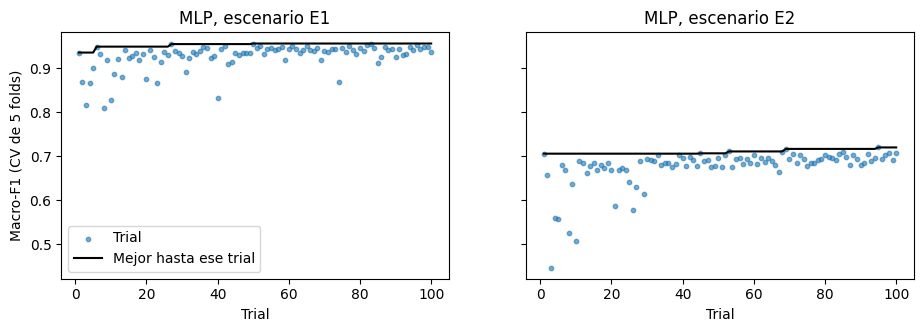

In [13]:
# Historial de Optuna del MLP: macro-F1 de cada trial y mejor valor acumulado (figura solo del notebook)
figura, ejes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for eje, escenario in zip(ejes, ESCENARIOS):
    valores = [t.value for t in ESTUDIOS[("MLP", escenario)]["estudio"].trials]
    eje.scatter(range(1, len(valores) + 1), valores, s=10, alpha=0.6, label="Trial")
    eje.plot(range(1, len(valores) + 1), np.maximum.accumulate(valores), color="black", label="Mejor hasta ese trial")
    eje.set_title(f"MLP, escenario {escenario}")
    eje.set_xlabel("Trial")
ejes[0].set_ylabel("Macro-F1 (CV de 5 folds)")
ejes[0].legend()
utilidades.guardar_figura(figura, "figura_07_optuna_historial_obesidad")
plt.show()

**Qué observamos:** en los dos escenarios hay *trials* muy malos al inicio (en E2, uno con 0.45), cuando TPE todavía explora el espacio. Después la búsqueda se concentra en configuraciones buenas: en E1 casi todos los *trials* superan 0.90, y en E2 se agrupan entre 0.68 y 0.71. La mejora del mejor valor tras los primeros *trials* es pequeña (en E2, de 0.706 a 0.720), así que 100 *trials* bastan.

## 5. GridSearchCV frente a Optuna

**Qué hacemos:** buscamos los hiperparámetros de KNN en el escenario principal (E2) con la malla completa del mismo espacio y comparamos con los 50 *trials* de Optuna.

**Por qué:** `GridSearchCV` es la herramienta del curso: prueba todas las combinaciones. La comparación mide calidad (mejor macro-F1), costo (configuraciones evaluadas) y tiempo, con los mismos folds (diseño, §8).

In [14]:
# Malla completa del espacio de KNN (50 × 2 × 2 = 200 combinaciones)
columnas = ESCENARIOS[PRINCIPAL]
knn = crear_pipeline(KNeighborsClassifier(), PRINCIPAL)
MALLA_KNN = {"modelo__n_neighbors": list(range(1, 51)), "modelo__weights": ["uniform", "distance"],
             "modelo__p": [1, 2]}
inicio = time.time()
malla = GridSearchCV(knn, MALLA_KNN, cv=CV, scoring="f1_macro", n_jobs=-1).fit(train[columnas], y_train)
segundos_malla = time.time() - inicio

In [15]:
# Tabla 5: calidad, costo y tiempo de cada búsqueda (mismo espacio, mismos folds)
optuna_knn = ESTUDIOS[("KNN", PRINCIPAL)]
tabla_busqueda = pd.DataFrame([
    {"busqueda": "GridSearchCV (malla completa)", "evaluaciones": len(malla.cv_results_["params"]),
     "mejor_macro_f1_cv": malla.best_score_, "segundos": segundos_malla, "mejores_parametros": malla.best_params_},
    {"busqueda": "Optuna (TPE)", "evaluaciones": len(optuna_knn["estudio"].trials),
     "mejor_macro_f1_cv": optuna_knn["estudio"].best_value, "segundos": optuna_knn["segundos"],
     "mejores_parametros": optuna_knn["estudio"].best_params}])
tabla_busqueda.round(3)

,busqueda,evaluaciones,mejor_macro_f1_cv,segundos,mejores_parametros
0,GridSearchCV (malla completa),200,0.67,1.298,"{'modelo__n_neighbors': 5, 'modelo__p': 1, 'mo..."
1,Optuna (TPE),50,0.67,5.426,"{'n_neighbors': 5, 'weights': 'distance', 'p': 1}"


In [16]:
# Tamaño que tendría una malla mínima del espacio del MLP (argumento de costo, no se ejecuta)
valores_por_hiperparametro = {"capas y neuronas (3 anchos por capa)": 3 + 3**2 + 3**3, "activation": 2,
                              "solver": 2, "alpha": 4, "learning_rate_init": 4, "batch_size": 4}
combinaciones = int(np.prod(list(valores_por_hiperparametro.values())))
segundos_por_evaluacion = ESTUDIOS[("MLP", PRINCIPAL)]["segundos"] / 100
print(f"Malla mínima del MLP: {combinaciones} combinaciones ≈ "
      f"{combinaciones * segundos_por_evaluacion / 3600:.1f} horas con el costo medio medido")

Malla mínima del MLP: 9984 combinaciones ≈ 0.8 horas con el costo medio medido


**Qué observamos:** las dos búsquedas encuentran la misma configuración de KNN (5 vecinos, ponderados por distancia, Manhattan) y el mismo macro-F1 (0.670), pero Optuna evalúa 4 veces menos configuraciones (50 frente a 200). En tiempo, la malla fue más rápida en esta máquina (1.3 s frente a 5.4 s), porque `GridSearchCV` reparte todas las combinaciones entre los núcleos mientras Optuna evalúa los *trials* uno tras otro, y KNN es tan barato que domina ese costo fijo. La ventaja de Optuna aparece con modelos caros: una malla mínima del MLP tendría 9984 combinaciones, unas 0.8 horas con el costo medido, frente a los 100 *trials* usados.

## 6. Balanceo de clases

**No aplica en obesidad.** Las siete clases ya están balanceadas porque los autores generaron el 77% de las filas con SMOTE (notebook 03, sección 4); volver a sobremuestrear multiplicaría las filas sintéticas (diseño, §5).

In [17]:
# Lista de ablaciones (en obesidad solo habrá selección de variables)
X, ABLACIONES = train[ESCENARIOS[PRINCIPAL]], []

## 7. Selección de variables

**Qué hacemos:** agregamos un selector L1 (Lasso logístico) entre el preprocesamiento y el modelo, y lo comparamos con usar todas las variables.

**Por qué:** la consigna pide selección de *features*. Lasso se vio en clase; dentro del `Pipeline` se aprende en cada fold y evita el sesgo de elegir variables mirando todos los datos (diseño, §6).

In [18]:
# Mejor configuración de KNN y MLP con selector L1 (CV 5×3, escenario principal)
for nombre in ["KNN", "MLP"]:
    trial = optuna.trial.FixedTrial(ESTUDIOS[(nombre, PRINCIPAL)]["estudio"].best_params)
    con_seleccion = pipeline_desde_trial(trial, nombre, PRINCIPAL, seleccion=True)
    puntajes = utilidades.evaluar_cv(con_seleccion, X, y_train, grupos=GRUPOS,
                                     repeticiones=3, semilla=utilidades.SEMILLA_COMPARATIVA)
    sin_seleccion = utilidades.evaluar_cv(MODELOS_FINALES[(nombre, PRINCIPAL)], X, y_train, grupos=GRUPOS,
                                          repeticiones=3, semilla=utilidades.SEMILLA_COMPARATIVA)
    for variante, valores in [("todas las variables", sin_seleccion), ("selector L1", puntajes)]:
        ABLACIONES.append({"ablacion": "seleccion", "modelo": nombre, "variante": variante,
                           "media": valores.mean(), "desviacion": valores.std()})
tabla_ablaciones = pd.DataFrame(ABLACIONES)
tabla_ablaciones.round(3)

,ablacion,modelo,variante,media,desviacion
0,seleccion,KNN,todas las variables,0.658,0.022
1,seleccion,KNN,selector L1,0.658,0.022
2,seleccion,MLP,todas las variables,0.701,0.032
3,seleccion,MLP,selector L1,0.701,0.032


In [19]:
# ¿Cuántas columnas conserva el selector L1 si se ajusta con todo el train?
selector = Pipeline([("preprocesamiento", utilidades.crear_preprocesador("obesidad", PRINCIPAL)),
                     ("seleccion", SelectFromModel(LogisticRegression(penalty="l1", solver="saga", C=1.0, max_iter=5000)))])
selector.fit(X, y_train)
conservadas = selector.named_steps["seleccion"].get_support()
nombres = selector.named_steps["preprocesamiento"].get_feature_names_out()
print("Columnas conservadas:", conservadas.sum(), "de", len(conservadas))
print("Eliminadas:", list(nombres[~conservadas]))

Columnas conservadas: 17 de 17
Eliminadas: []


**Qué observamos:** el selector L1 conserva las 17 columnas y el macro-F1 no cambia (0.658 en KNN y 0.701 en el MLP). Con tan pocas variables, todas aportan algo y Lasso no elimina ninguna; en este escenario la selección no hace falta, y eso también es un resultado.

## 8. Comparativa por validación cruzada

**Qué hacemos:** evaluamos todas las configuraciones finales con CV de 5 folds repetida 3 veces y otra semilla.

**Por qué:** la comparativa reporta media ± desviación de 15 valores por modelo (diseño, §10). Usar otra semilla que en la búsqueda reduce el optimismo de evaluar con los mismos folds que eligieron los hiperparámetros. Regla fijada de antemano: la configuración final de cada modelo es la mejor de su búsqueda; las ablaciones de las secciones 6 y 7 se reportan, pero no la cambian.

In [20]:
# CV 5×3 de cada configuración final (puede tardar unos minutos)
PUNTAJES, COMPARATIVA = {}, []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for (nombre, escenario), pipeline in MODELOS_FINALES.items():
        valores = utilidades.evaluar_cv(pipeline, train[ESCENARIOS[escenario]], y_train, grupos=GRUPOS,
                                        repeticiones=3, semilla=utilidades.SEMILLA_COMPARATIVA)
        PUNTAJES[(nombre, escenario)] = valores
        COMPARATIVA.append({"modelo": nombre, "escenario": escenario, "media": valores.mean(),
                            "desviacion": valores.std(), "minimo": valores.min(), "maximo": valores.max()})
tabla_comparativa = pd.DataFrame(COMPARATIVA).sort_values(["escenario", "media"], ascending=[True, False])
tabla_comparativa.round(3)

,modelo,escenario,media,desviacion,minimo,maximo
5,MLP,E1,0.950,0.011,0.919,0.969
2,Árbol (autores),E1,0.938,0.012,0.916,0.956
4,KNN,E1,0.812,0.014,0.787,0.844
0,Dummy,E1,0.041,0.001,0.039,0.042
7,MLP,E2,0.701,0.032,0.632,0.741
3,Árbol (autores),E2,0.662,0.021,0.619,0.695
6,KNN,E2,0.658,0.022,0.606,0.691
1,Dummy,E2,0.041,0.001,0.039,0.042


In [21]:
# Wilcoxon (escenario principal): mejor método nuevo frente a la referencia de los autores
nuevos = tabla_comparativa[(tabla_comparativa["escenario"] == PRINCIPAL) & tabla_comparativa["modelo"].isin(["KNN", "MLP"])]
MEJOR = nuevos.sort_values("media", ascending=False)["modelo"].iloc[0]
referencia = "Árbol (autores)"
estadistico, p_valor = wilcoxon(PUNTAJES[(MEJOR, PRINCIPAL)], PUNTAJES[(referencia, PRINCIPAL)])
diferencia = PUNTAJES[(MEJOR, PRINCIPAL)].mean() - PUNTAJES[(referencia, PRINCIPAL)].mean()
print(f"Mejor método nuevo en {PRINCIPAL}: {MEJOR}. Diferencia de macro-F1 frente a {referencia}: {diferencia:+.3f}")
print(f"Wilcoxon sobre 15 folds pareados: estadístico = {estadistico:.1f}, p = {p_valor:.4f}")
print("Los folds de una CV repetida no son independientes: el valor p es orientativo (diseño, §10).")

Mejor método nuevo en E2: MLP. Diferencia de macro-F1 frente a Árbol (autores): +0.039
Wilcoxon sobre 15 folds pareados: estadístico = 6.0, p = 0.0009
Los folds de una CV repetida no son independientes: el valor p es orientativo (diseño, §10).


**Qué observamos:** en E1, el MLP obtiene 0.950 ± 0.011, el árbol 0.938 ± 0.012 y KNN 0.812 ± 0.014. En E2, el escenario principal, el MLP obtiene 0.701 ± 0.032, el árbol 0.662 ± 0.021 y KNN 0.658 ± 0.022; el Dummy queda en 0.041. El MLP supera al árbol de los autores en 0.039, con Wilcoxon *p* = 0.0009 (orientativo). Sin estatura ni peso, los hábitos permiten clasificar bastante mejor que el azar, pero lejos del 0.95 de E1.

## 8.1 Sensibilidad del protocolo

**Qué hacemos:** repetimos la CV 5×3 de las configuraciones finales en el escenario principal con dos protocolos menos cuidadosos: sin redondear y sin agrupar (ingenuo), y redondeado pero sin agrupar.

**Por qué:** cuantifica cuánto inflan las métricas la huella de SMOTE y las filas idénticas (diseño, §7.6). Se usan solo las filas del train y los mismos hiperparámetros, así que no se toca el test.

In [22]:
# Mismas filas del train, pero con los valores originales (sin redondear) del CSV sin duplicados
original = pd.read_csv("datos/ObesityDataSet_raw_and_data_sinthetic.csv").drop_duplicates().reset_index(drop=True)
original["CALC"] = original["CALC"].replace("Always", "Frequently")   # única fusión necesaria para codificar
train_original = original.loc[train.index]
columnas = ESCENARIOS[PRINCIPAL]
protocolos = {"ingenuo: sin redondear, sin agrupar": (train_original[columnas], None),
              "redondeado, sin agrupar": (train[columnas], None),
              "elegido: redondeado y agrupado": (train[columnas], GRUPOS)}

In [23]:
# Tabla 7: macro-F1 (CV 5×3) de cada modelo con cada protocolo
SENSIBILIDAD = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for protocolo, (X_protocolo, grupos) in protocolos.items():
        for nombre in ["Árbol (autores)", "KNN", "MLP"]:
            valores = utilidades.evaluar_cv(MODELOS_FINALES[(nombre, PRINCIPAL)], X_protocolo, y_train, grupos=grupos,
                                            repeticiones=3, semilla=utilidades.SEMILLA_COMPARATIVA)
            SENSIBILIDAD.append({"protocolo": protocolo, "modelo": nombre,
                                 "media": valores.mean(), "desviacion": valores.std()})
tabla_sensibilidad = pd.DataFrame(SENSIBILIDAD)
tabla_sensibilidad.pivot(index="modelo", columns="protocolo", values="media").round(3)

protocolo,elegido: redondeado y agrupado,"ingenuo: sin redondear, sin agrupar","redondeado, sin agrupar"
modelo,,,
KNN,0.658,0.776,0.716
MLP,0.701,0.752,0.728
Árbol (autores),0.662,0.721,0.709


**Qué observamos:** con el protocolo ingenuo (sin redondear y sin agrupar), el macro-F1 sube a 0.776 en KNN, 0.752 en el MLP y 0.721 en el árbol. Frente al protocolo elegido, la inflación es de 11.8 puntos en KNN, 5.1 en el MLP y 5.9 en el árbol. Solo redondear ya baja KNN a 0.716; agrupar quita otros 5.8 puntos. KNN es el más inflado porque decide por vecinos cercanos, y las copias sintéticas casi idénticas son exactamente eso. El protocolo cambia la conclusión: con el ingenuo, KNN parecería el mejor modelo; con el elegido, es el peor.

## 9. Evaluación final en el test

**Qué hacemos:** reentrenamos cada configuración final con todo el train y la evaluamos una sola vez en el test.

**Por qué:** el test de reserva da la estimación sin sesgo del desempeño; después de verlo no se cambia ninguna decisión (diseño, §7.5).

In [24]:
# Entrenar con todo el train y medir en el test (tabla 4)
MODELOS_ENTRENADOS, METRICAS_TEST = {}, []
for (nombre, escenario), pipeline in MODELOS_FINALES.items():
    columnas = ESCENARIOS[escenario]
    modelo = clone(pipeline).fit(train[columnas], y_train)
    MODELOS_ENTRENADOS[(nombre, escenario)] = modelo
    METRICAS_TEST.append({"modelo": nombre, "escenario": escenario,
                          **utilidades.metricas_test(modelo, test[columnas], y_test, "obesidad")})
tabla_test = pd.DataFrame(METRICAS_TEST)
tabla_test.round(3)

,modelo,escenario,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr,kappa_cuadratico
0,Dummy,E1,0.171,0.143,0.024,0.143,0.042,0.500,0.000
1,Dummy,E2,0.171,0.143,0.024,0.143,0.042,0.500,0.000
2,Árbol (autores),E1,0.933,0.931,0.933,0.931,0.931,0.960,0.990
3,Árbol (autores),E2,0.726,0.727,0.728,0.727,0.727,0.868,0.864
4,KNN,E1,0.849,0.847,0.845,0.847,0.843,0.958,0.957
5,MLP,E1,0.947,0.945,0.949,0.945,0.946,0.998,0.993
6,KNN,E2,0.690,0.689,0.689,0.689,0.681,0.901,0.778
7,MLP,E2,0.709,0.706,0.712,0.706,0.708,0.923,0.849


In [25]:
# Convergencia del MLP final: iteraciones usadas frente al máximo permitido
for escenario in ESCENARIOS:
    mlp = MODELOS_ENTRENADOS[("MLP", escenario)].named_steps["modelo"]
    print(f"MLP {escenario}: {mlp.n_iter_} iteraciones de {mlp.max_iter} (early stopping)")

MLP E1: 37 iteraciones de 500 (early stopping)
MLP E2: 29 iteraciones de 500 (early stopping)


In [26]:
# F1 de cada clase en el test (escenario principal)
from sklearn.metrics import f1_score
f1_por_clase = {nombre: f1_score(y_test, MODELOS_ENTRENADOS[(nombre, PRINCIPAL)].predict(test[ESCENARIOS[PRINCIPAL]]),
                                 average=None)
                for nombre in [m for m, e in MODELOS_ENTRENADOS if e == PRINCIPAL]}
pd.DataFrame(f1_por_clase, index=CLASES).round(3)

,Dummy,Árbol (autores),KNN,MLP
Insufficient_Weight,0.000,0.821,0.744,0.755
Normal_Weight,0.000,0.523,0.505,0.552
Overweight_Level_I,0.000,0.696,0.569,0.627
Overweight_Level_II,0.000,0.661,0.642,0.586
Obesity_Type_I,0.292,0.621,0.612,0.658
Obesity_Type_II,0.000,0.807,0.791,0.826
Obesity_Type_III,0.000,0.959,0.905,0.951


In [27]:
# Sensibilidad: métricas del test solo en las filas probablemente reales (escenario principal)
from sklearn.metrics import accuracy_score, cohen_kappa_score
reales = test["probablemente_real"].to_numpy()
print("Filas reales en el test por clase:", dict(zip(CLASES, np.bincount(y_test[reales], minlength=7))))
filas_reales = []
for nombre in ["Árbol (autores)", "KNN", "MLP"]:
    prediccion = MODELOS_ENTRENADOS[(nombre, PRINCIPAL)].predict(test[ESCENARIOS[PRINCIPAL]][reales])
    filas_reales.append({"modelo": nombre, "accuracy": accuracy_score(y_test[reales], prediccion),
                         "f1_macro": f1_score(y_test[reales], prediccion, average="macro"),
                         "kappa_cuadratico": cohen_kappa_score(y_test[reales], prediccion, weights="quadratic")})
tabla_reales = pd.DataFrame(filas_reales)
tabla_reales.round(3)

Filas reales en el test por clase: {'Insufficient_Weight': np.int64(5), 'Normal_Weight': np.int64(57), 'Overweight_Level_I': np.int64(12), 'Overweight_Level_II': np.int64(12), 'Obesity_Type_I': np.int64(9), 'Obesity_Type_II': np.int64(3), 'Obesity_Type_III': np.int64(1)}


,modelo,accuracy,f1_macro,kappa_cuadratico
0,Árbol (autores),0.455,0.266,0.352
1,KNN,0.414,0.289,0.296
2,MLP,0.455,0.251,0.321


**Qué observamos:** en el test, E1 confirma el techo que da el IMC: el MLP llega a 0.946 de macro-F1 y 0.993 de kappa ponderado. En E2, el árbol obtiene 0.727 (kappa 0.864), el MLP 0.708 (kappa 0.849) y KNN 0.681 (kappa 0.778). En el test el árbol supera al MLP, al revés que en la CV; la diferencia (0.019) es menor que la variabilidad entre *folds* del MLP (0.032) y proviene de una sola partición de 416 filas, así que no se cambia ninguna decisión (§7.5). El MLP final converge por *early stopping* en 37 y 29 iteraciones. Por clase, el MLP en E2 acierta mejor Obesity_Type_III (F1 0.951) y Obesity_Type_II (0.826), y peor Normal_Weight (0.552) y Overweight_Level_II (0.586). En las 99 filas probablemente reales del test (57 de Normal_Weight y solo una de Obesity_Type_III), el macro-F1 cae a 0.25–0.29 y el kappa a 0.30–0.35 en los tres modelos. Con tan pocas filas reales es una señal descriptiva, pero indica que buena parte del desempeño proviene de patrones de los datos sintéticos.

## 10. Interpretación del mejor modelo

**Qué hacemos:** analizamos el mejor método nuevo del escenario principal con su matriz de confusión, la importancia por permutación de cada variable y la curva de aprendizaje.

**Por qué:** explican qué aprendió el modelo, en qué clases se equivoca y si sufre de sesgo o de varianza (diseño, §10). Hay que revisar el peso de Gender, que puede ser un artefacto del sobremuestreo.

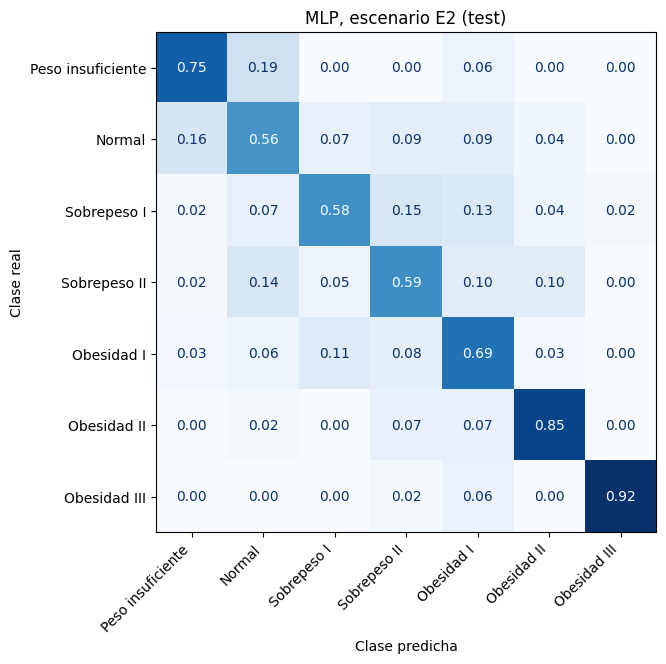

In [28]:
# Figura 4: matriz de confusión del mejor modelo en el test (proporciones por clase real)
from sklearn.metrics import ConfusionMatrixDisplay
modelo_mejor = MODELOS_ENTRENADOS[(MEJOR, PRINCIPAL)]
X_test = test[ESCENARIOS[PRINCIPAL]]
figura, eje = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay.from_estimator(modelo_mejor, X_test, y_test, display_labels=ETIQUETAS, normalize="true",
                                      values_format=".2f", cmap="Blues", ax=eje, colorbar=False)
eje.set_title(f"{MEJOR}, escenario {PRINCIPAL} (test)")
eje.set_xlabel("Clase predicha")
eje.set_ylabel("Clase real")
plt.xticks(rotation=45, ha="right")
utilidades.guardar_figura(figura, "figura_04_confusion_obesidad")
plt.show()

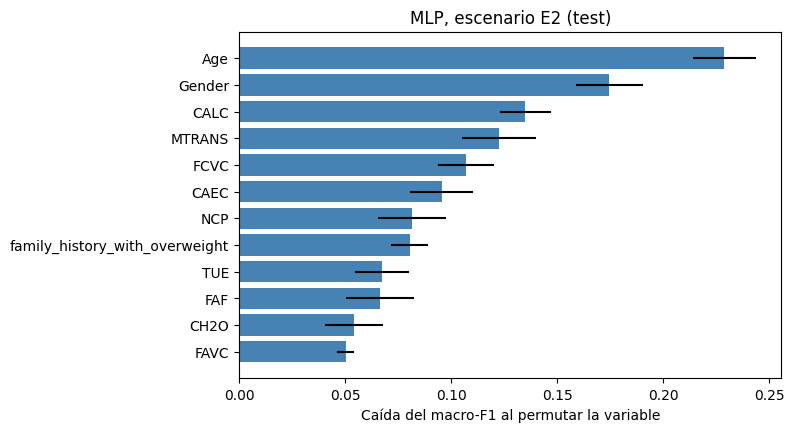

,media,desviacion
Age,0.229,0.015
Gender,0.175,0.016
CALC,0.135,0.012
MTRANS,0.123,0.018
FCVC,0.107,0.013
CAEC,0.096,0.015
NCP,0.082,0.016
family_history_with_overweight,0.080,0.009
TUE,0.067,0.013
FAF,0.067,0.016


In [29]:
# Figura 5: importancia por permutación en el test (caída del macro-F1 al desordenar cada variable)
from sklearn.inspection import permutation_importance
importancia = permutation_importance(modelo_mejor, X_test, y_test, scoring="f1_macro",
                                     n_repeats=10, random_state=SEMILLA, n_jobs=-1)
tabla_importancia = pd.DataFrame({"media": importancia.importances_mean, "desviacion": importancia.importances_std},
                                 index=X_test.columns).sort_values("media", ascending=False)
figura, eje = plt.subplots(figsize=(7, 4.5))
principales = tabla_importancia.head(12).iloc[::-1]
eje.barh(principales.index, principales["media"], xerr=principales["desviacion"], color="steelblue")
eje.set_xlabel("Caída del macro-F1 al permutar la variable")
eje.set_title(f"{MEJOR}, escenario {PRINCIPAL} (test)")
utilidades.guardar_figura(figura, "figura_05_importancia_obesidad")
plt.show()
tabla_importancia.head(12).round(3)

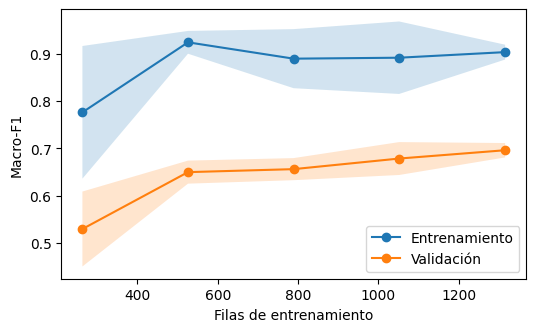

In [30]:
# Figura 6: curva de aprendizaje del mejor modelo (CV de 5 folds sobre el train)
from sklearn.model_selection import learning_curve
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    tamanos, puntaje_train, puntaje_validacion = learning_curve(
        MODELOS_FINALES[(MEJOR, PRINCIPAL)], train[ESCENARIOS[PRINCIPAL]], y_train, cv=CV,
        scoring="f1_macro", train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1,
        shuffle=True, random_state=SEMILLA)   # barajar: el CSV de obesidad viene ordenado por clase
figura, eje = plt.subplots(figsize=(6, 3.5))
for valores, etiqueta in [(puntaje_train, "Entrenamiento"), (puntaje_validacion, "Validación")]:
    eje.plot(tamanos, valores.mean(axis=1), marker="o", label=etiqueta)
    eje.fill_between(tamanos, valores.mean(axis=1) - valores.std(axis=1), valores.mean(axis=1) + valores.std(axis=1), alpha=0.2)
eje.set_xlabel("Filas de entrenamiento")
eje.set_ylabel("Macro-F1")
eje.legend()
utilidades.guardar_figura(figura, "figura_06_curva_aprendizaje_obesidad")
plt.show()

**Qué observamos:** la matriz de confusión muestra que la mayoría de los errores ocurren entre clases vecinas: Normal y Peso insuficiente se confunden en ambos sentidos (16% y 19%), y Sobrepeso I se confunde con Sobrepeso II (15%). Por eso el kappa ponderado (0.849) es alto aunque el macro-F1 sea moderado. Obesidad II (85%) y Obesidad III (92%) son las clases mejor reconocidas. La importancia por permutación coloca a Age (0.229) y a Gender (0.175) en los dos primeros lugares, seguidas de CALC, MTRANS y FCVC. El peso de Gender refleja el artefacto del sobremuestreo (Obesity_Type_II casi solo hombres y Obesity_Type_III solo mujeres) y explica en parte el buen desempeño en esas dos clases; no es una relación causal. La curva de aprendizaje muestra una brecha de unos 0.20 puntos entre entrenamiento (0.90) y validación (0.70): hay varianza, y la validación sigue subiendo lentamente, así que más datos reales ayudarían.

## 11. Registro de resultados

**Qué hacemos:** guardamos las tablas del reporte y el registro largo de resultados de este notebook.

**Por qué:** el reporte toma sus cifras solo de `resultados/` (diseño, §11.2).

In [31]:
# Registro largo: comparativa y ablaciones (CV) y métricas del test
for fila in COMPARATIVA:
    configuracion = MODELOS_FINALES[(fila["modelo"], fila["escenario"])].named_steps["modelo"].get_params()
    utilidades.registrar_resultado(filas_resultados, "obesidad", fila["escenario"], fila["modelo"], configuracion,
                                   "f1_macro", fila["media"], fila["desviacion"], "CV")
for fila in ABLACIONES:
    utilidades.registrar_resultado(filas_resultados, "obesidad", PRINCIPAL, fila["modelo"], fila["ablacion"] + ": " + fila["variante"],
                                   "f1_macro", fila["media"], fila["desviacion"], "CV")
for fila in METRICAS_TEST:
    for metrica, valor in fila.items():
        if metrica not in ["modelo", "escenario"]:
            utilidades.registrar_resultado(filas_resultados, "obesidad", fila["escenario"], fila["modelo"], "final",
                                           metrica, valor, None, "test")
print("Filas registradas:", len(filas_resultados))

Filas registradas: 68


In [32]:
# Guardar las tablas del reporte y el registro
utilidades.guardar_tabla(tabla_hiperparametros, "tabla_02_hiperparametros_obesidad")
utilidades.guardar_tabla(tabla_comparativa, "tabla_03_comparativa_cv_obesidad")
utilidades.guardar_tabla(tabla_test, "tabla_04_metricas_test_obesidad")
utilidades.guardar_tabla(tabla_busqueda, "tabla_05_grid_vs_optuna_obesidad")
utilidades.guardar_tabla(tabla_ablaciones, "tabla_06_ablaciones_obesidad")
utilidades.guardar_tabla(pd.DataFrame(filas_resultados), "resultados_obesidad")
sensibilidad = pd.concat([tabla_sensibilidad.assign(particion="CV 5×3 (train)"),
                          tabla_reales.melt(id_vars="modelo", var_name="metrica", value_name="media")
                                      .assign(protocolo="test, solo filas probablemente reales")])
utilidades.guardar_tabla(sensibilidad, "tabla_07_sensibilidad_protocolo_obesidad")
print("Tablas guardadas en resultados/tablas/")

Tablas guardadas en resultados/tablas/


## Guardar resultados en GitHub (solo corrida oficial en Colab)

**Qué hacemos:** subimos a `main` los archivos de `resultados/` que genera este notebook.

**Por qué:** las cifras del reporte deben salir de la misma corrida que deja las salidas visibles en el notebook (§12, regla 4). En VS Code esta celda no hace nada; Marcelo hace el *commit* desde VS Code. Después de esta celda, guardar el notebook con *File → Save a copy in GitHub*.

In [33]:
# Celda final. Cambiar a True solo en la corrida oficial, después de "Reiniciar y ejecutar todo".
import glob

GUARDAR_EN_GITHUB = False
PATRONES_DE_ESTE_NOTEBOOK = ["resultados/tablas/tabla_0[2-7]_*obesidad.csv", "resultados/tablas/resultados_obesidad.csv", "resultados/figuras/figura_0[4-8]_*obesidad.png"]
if EN_COLAB and GUARDAR_EN_GITHUB:
    archivos = " ".join(f for patron in PATRONES_DE_ESTE_NOTEBOOK for f in sorted(glob.glob(patron)))
    nombre, correo = userdata.get("GITHUB_NOMBRE"), userdata.get("GITHUB_CORREO")
    !git config user.name "{nombre}"
    !git config user.email "{correo}"
    !git add {archivos}
    !git commit -q -m "04-obesidad: actualiza resultados de la corrida oficial"
    !git pull -q --rebase
    !git push -q
    print("Archivos subidos:", archivos)